In [1]:
import sys
import subprocess
import importlib.util

# Required libraries
packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "statsmodels": "statsmodels",
    "sklearn": "scikit-learn",
    "scipy": "scipy"
}

print("Checking required libraries...\n")

for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        print(f"{package} not found. Installing...")
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", package
        ])
        print(f"{package} installed successfully.\n")
    else:
        print(f"{package} is already installed.")

print("\nAll required libraries are ready!")

Checking required libraries...

numpy is already installed.
pandas is already installed.
matplotlib is already installed.
statsmodels is already installed.
scikit-learn is already installed.
scipy is already installed.

All required libraries are ready!


In [2]:
import pandas
import statsmodels
import scipy
import numpy

print("Pandas:", pandas.__version__)
print("Statsmodels:", statsmodels.__version__)
print("SciPy:", scipy.__version__)
print("NumPy:", numpy.__version__)

Pandas: 2.2.3
Statsmodels: 0.14.5
SciPy: 1.18.1
NumPy: 2.5.4


In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
dataset_path = "airline-passengers.csv"

dataset_url = (
    "https://raw.githubusercontent.com/"
    "jbrownlee/Datasets/master/airline-passengers.csv"
)

if os.path.exists(dataset_path):
    print("Dataset already exists. Loading local file...")
else:
    print("Dataset not found. Downloading...")
    df_download = pd.read_csv(dataset_url)
    df_download.to_csv(dataset_path, index=False)
    print("Dataset downloaded successfully!")

df = pd.read_csv(dataset_path)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

series = df["Passengers"].asfreq("MS").astype(float)

print("\nDataset loaded successfully!")
print("\nFirst 5 records:")
display(df.head())

print("\nDataset Information:")
print(df.info())

print("\nDataset Shape:", df.shape)

Dataset already exists. Loading local file...

Dataset loaded successfully!

First 5 records:


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB
None

Dataset Shape: (144, 1)


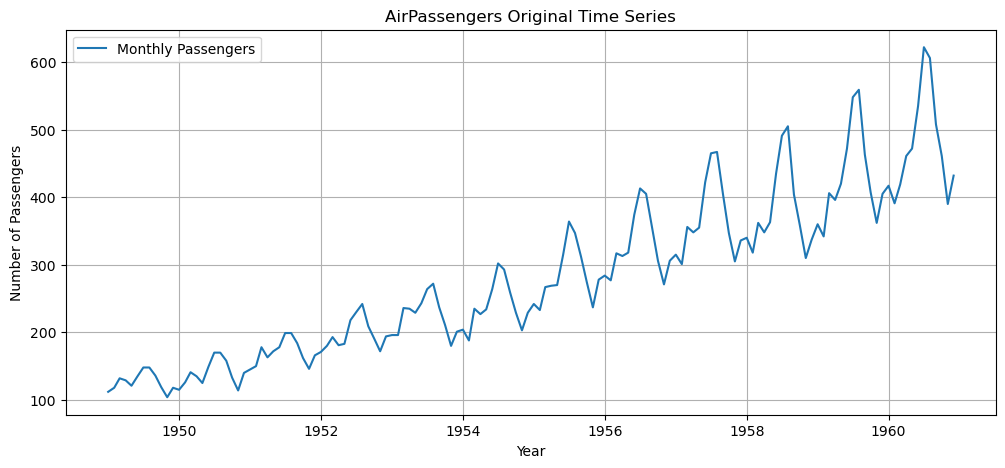

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(series, label="Monthly Passengers")

plt.title("AirPassengers Original Time Series")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()

plt.show()

In [6]:
def check_stationarity(data):

    result = adfuller(data.dropna())

    print("ADF Statistic:", result[0])
    print("p-value:", result[1])

    if result[1] <= 0.05:
        print("Conclusion: Series is Stationary")
    else:
        print("Conclusion: Series is Non-Stationary")


print("Original Series Stationarity:")
check_stationarity(series)

Original Series Stationarity:
ADF Statistic: 0.8153688792060576
p-value: 0.9918802434376411
Conclusion: Series is Non-Stationary


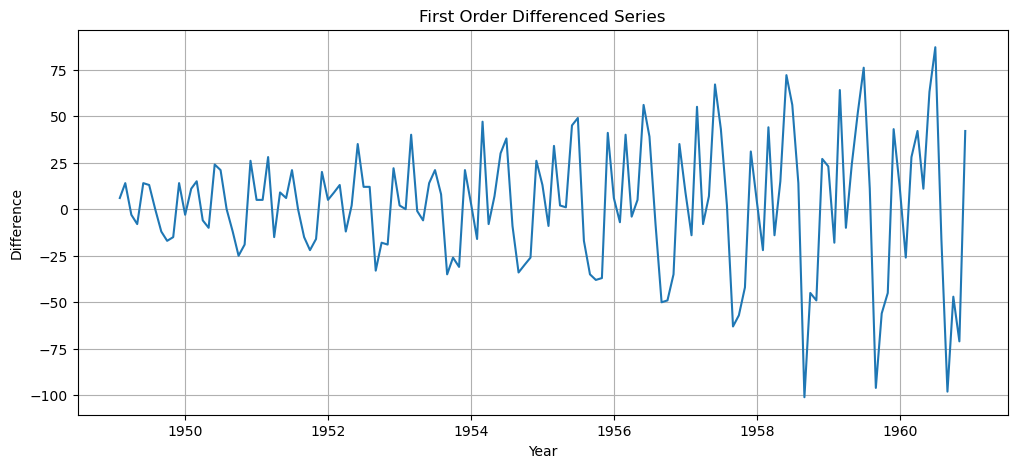

Stationarity After First Differencing:
ADF Statistic: -2.8292668241699968
p-value: 0.05421329028382589
Conclusion: Series is Non-Stationary


In [7]:
diff_series = series.diff().dropna()

plt.figure(figsize=(12, 5))

plt.plot(diff_series)

plt.title("First Order Differenced Series")
plt.xlabel("Year")
plt.ylabel("Difference")

plt.show()

print("Stationarity After First Differencing:")
check_stationarity(diff_series)

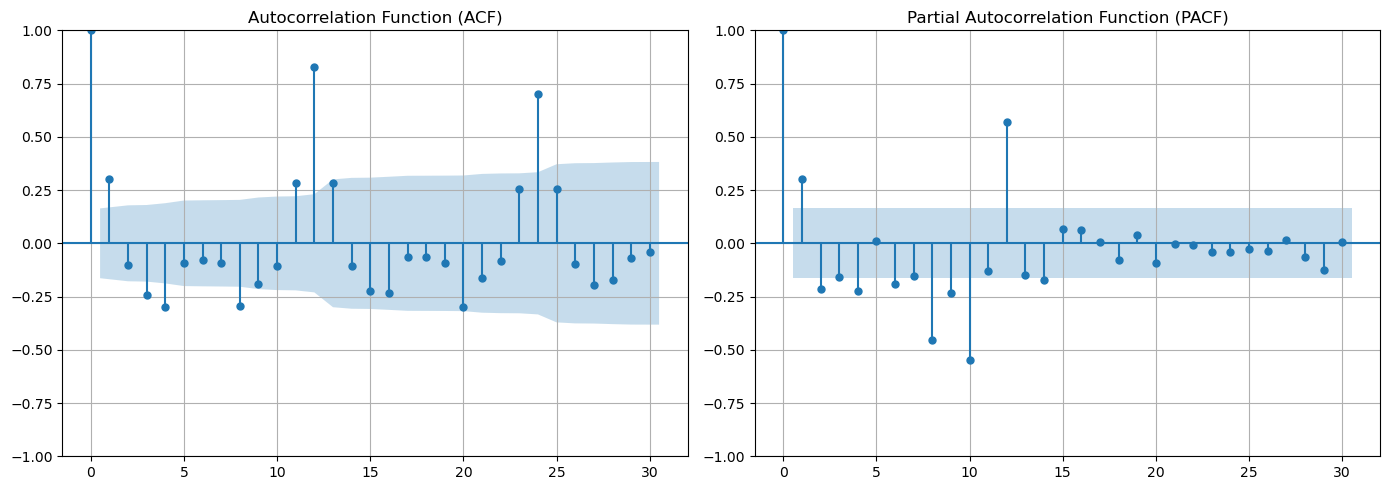

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(diff_series, lags=30, ax=axes[0])
plot_pacf(diff_series, lags=30, method="ywm", ax=axes[1])

axes[0].set_title("Autocorrelation Function (ACF)")
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

In [9]:
train_size = int(len(series) * 0.80)

train = series.iloc[:train_size]
test = series.iloc[train_size:]

print("Total observations:", len(series))
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Total observations: 144
Training observations: 115
Testing observations: 29

Training period: 1949-01-01 00:00:00 to 1958-07-01 00:00:00
Testing period: 1958-08-01 00:00:00 to 1960-12-01 00:00:00


In [10]:
arima_model = ARIMA(train, order=(2, 1, 2))

arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -523.758
Date:                Sun, 01 Nov 2026   AIC                           1057.516
Time:                        22:44:10   BIC                           1071.197
Sample:                    01-01-1949   HQIC                          1063.069
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3280      0.145      2.268      0.023       0.045       0.611
ar.L2          0.2521      0.165      1.528      0.126      -0.071       0.575
ma.L1         -0.0125      0.109     -0.114      0.9

In [11]:
arima_forecast = arima_fit.forecast(steps=len(test))

mae = mean_absolute_error(test, arima_forecast)

rmse = np.sqrt(mean_squared_error(test, arima_forecast))

print("ARIMA(2,1,2) RESULTS")

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("AIC:", round(arima_fit.aic, 3))

ARIMA(2,1,2) RESULTS
MAE: 63.545
RMSE: 82.513
AIC: 1057.516


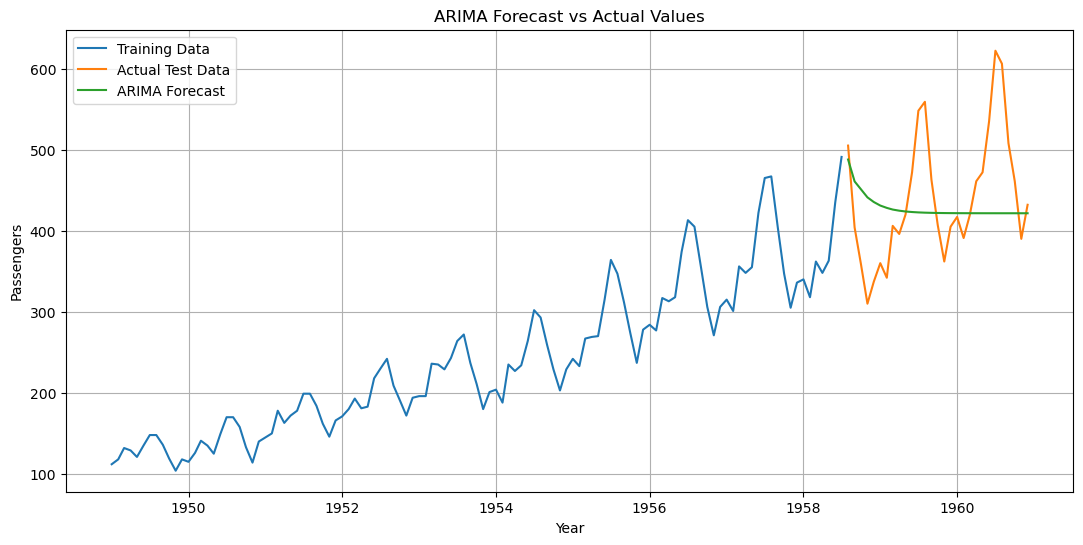

In [12]:
plt.figure(figsize=(13, 6))

plt.plot(train, label="Training Data")
plt.plot(test, label="Actual Test Data")
plt.plot(arima_forecast, label="ARIMA Forecast")

plt.title("ARIMA Forecast vs Actual Values")
plt.xlabel("Year")
plt.ylabel("Passengers")

plt.legend()
plt.show()

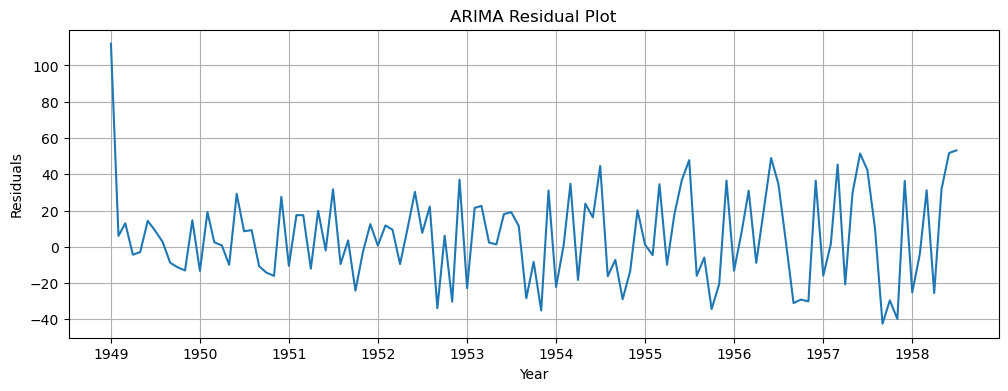

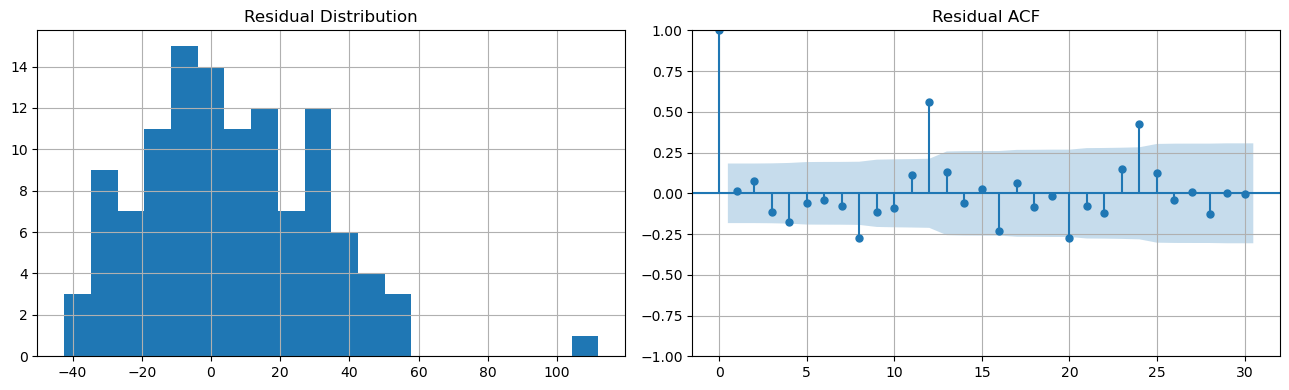

In [13]:
residuals = arima_fit.resid

plt.figure(figsize=(12, 4))

plt.plot(residuals)
plt.title("ARIMA Residual Plot")
plt.xlabel("Year")
plt.ylabel("Residuals")

plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(residuals, bins=20)
axes[0].set_title("Residual Distribution")

plot_acf(residuals.dropna(), lags=30, ax=axes[1])
axes[1].set_title("Residual ACF")

plt.tight_layout()
plt.show()

In [14]:
arima_orders = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

arima_results = []

for order in arima_orders:

    print("Fitting ARIMA", order)

    model = ARIMA(train, order=order)
    fitted_model = model.fit()

    forecast = fitted_model.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    arima_results.append({
        "ARIMA Order": str(order),
        "AIC": fitted_model.aic,
        "MAE": mae,
        "RMSE": rmse
    })

arima_comparison = pd.DataFrame(arima_results)

display(arima_comparison.round(3))

print("\nBest model based on RMSE:")

display(
    arima_comparison.sort_values("RMSE").head(1)
)

Fitting ARIMA (1, 1, 1)
Fitting ARIMA (2, 1, 1)
Fitting ARIMA (1, 1, 2)
Fitting ARIMA (2, 1, 2)


,ARIMA Order,AIC,MAE,RMSE
0,"(1, 1, 1)",1058.246,85.254,97.500
1,"(2, 1, 1)",1058.648,60.529,82.621
2,"(1, 1, 2)",1057.328,62.063,82.636
3,"(2, 1, 2)",1057.516,63.545,82.513



Best model based on RMSE:


,ARIMA Order,AIC,MAE,RMSE
3,"(2, 1, 2)",1057.516178,63.545311,82.513011


In [15]:
differencing_results = []

for d in [0, 1]:

    model = ARIMA(train, order=(2, d, 2))
    fitted_model = model.fit()

    forecast = fitted_model.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    differencing_results.append({
        "Differencing (d)": d,
        "AIC": fitted_model.aic,
        "MAE": mae,
        "RMSE": rmse
    })

differencing_comparison = pd.DataFrame(differencing_results)

display(differencing_comparison.round(3))

,Differencing (d),AIC,MAE,RMSE
0,0,1074.541,92.256,114.903
1,1,1057.516,63.545,82.513


In [16]:
horizons = [6, 12, 24]

horizon_results = []

for horizon in horizons:

    actual = test.iloc[:horizon]

    model = ARIMA(train, order=(2, 1, 2))
    fitted_model = model.fit()

    forecast = fitted_model.forecast(steps=horizon)

    mae = mean_absolute_error(actual, forecast)
    rmse = np.sqrt(mean_squared_error(actual, forecast))

    horizon_results.append({
        "Forecast Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse
    })

horizon_comparison = pd.DataFrame(horizon_results)

display(horizon_comparison.round(3))

,Forecast Horizon,MAE,RMSE
0,6,77.787,85.581
1,12,64.982,76.775
2,24,62.103,79.919


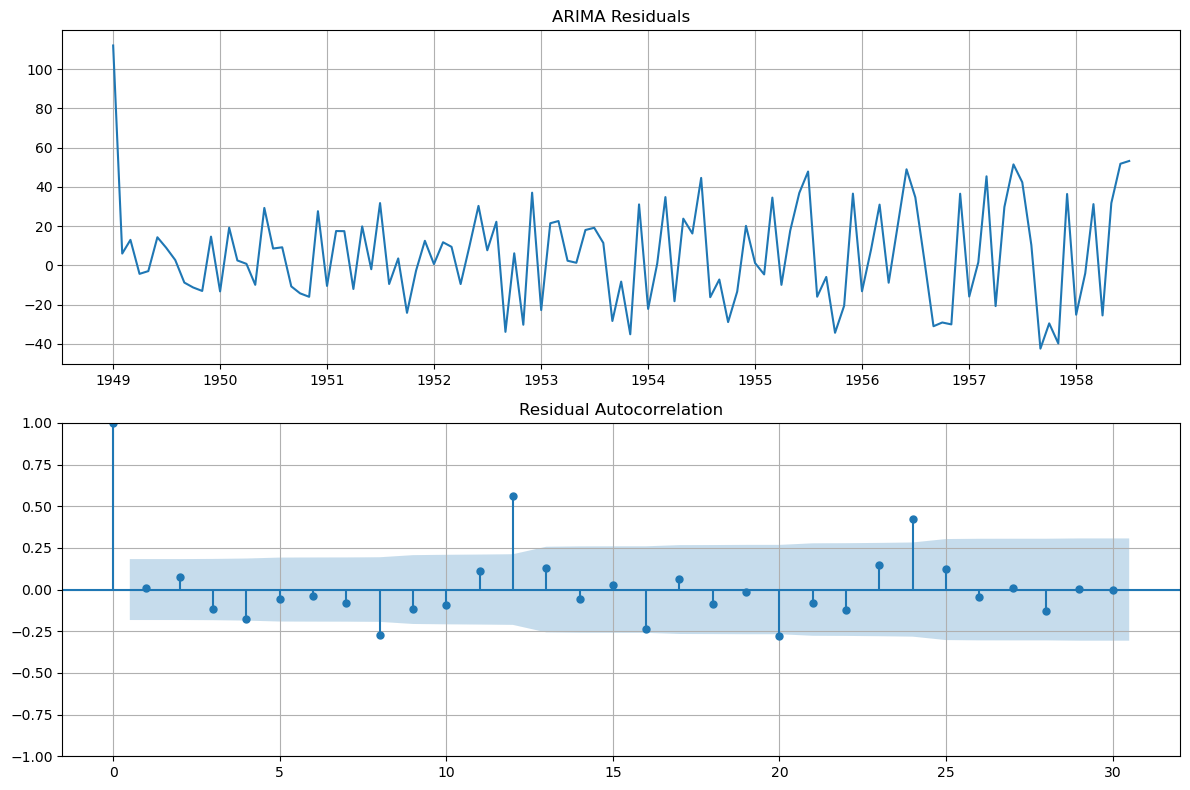

In [17]:
best_arima_model = ARIMA(train, order=(2, 1, 2)).fit()

residuals = best_arima_model.resid

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(residuals)
axes[0].set_title("ARIMA Residuals")

plot_acf(residuals.dropna(), lags=30, ax=axes[1])
axes[1].set_title("Residual Autocorrelation")

plt.tight_layout()
plt.show()

   YEAR  SUNACTIVITY
0  1700          5.0
1  1701         11.0
2  1702         16.0
3  1703         23.0
4  1704         36.0


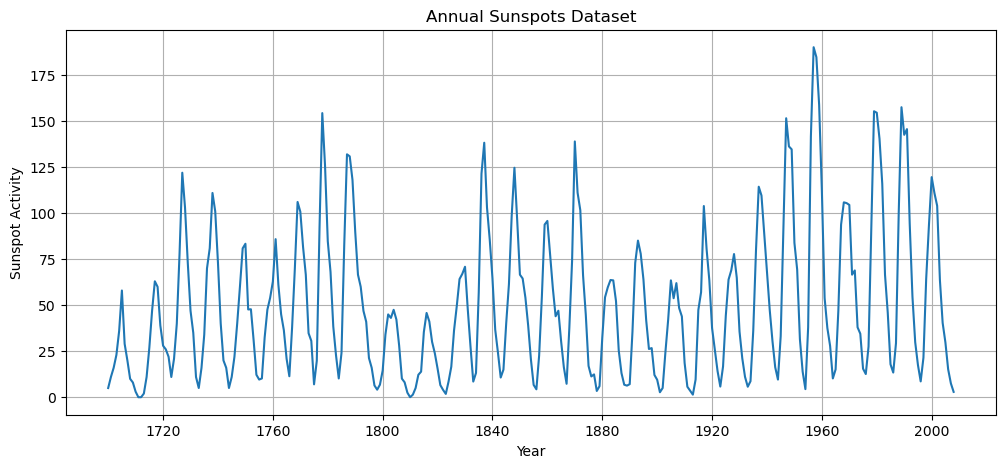

In [18]:
sunspots = pd.read_csv(
    "https://raw.githubusercontent.com/"
    "statsmodels/statsmodels/main/"
    "statsmodels/datasets/sunspots/sunspots.csv"
)

print(sunspots.head())

sunspot_series = sunspots["SUNACTIVITY"].astype(float)

sunspot_series.index = pd.date_range(
    start="1700",
    periods=len(sunspot_series),
    freq="YS"
)

plt.figure(figsize=(12, 5))

plt.plot(sunspot_series)

plt.title("Annual Sunspots Dataset")
plt.xlabel("Year")
plt.ylabel("Sunspot Activity")

plt.show()

SUNSPOTS ARIMA RESULTS
MAE: 33.161
RMSE: 40.228
AIC: 2020.545


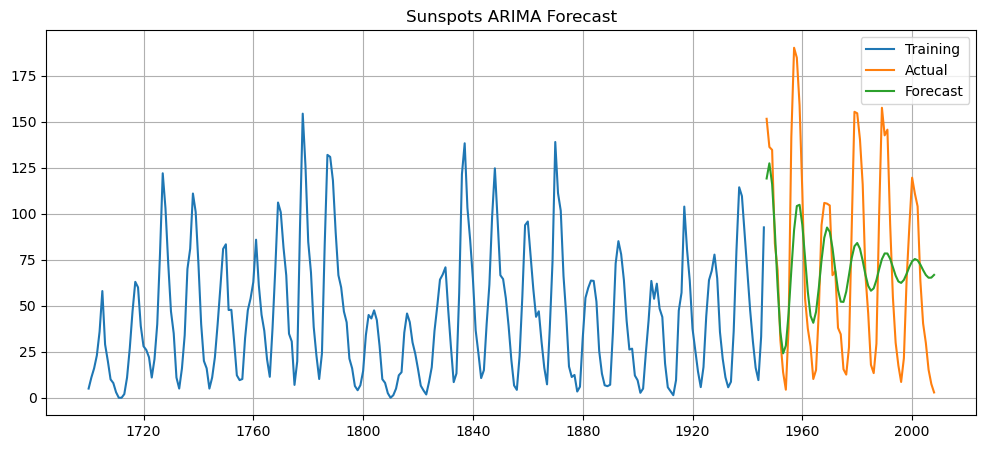

In [19]:
sunspot_split = int(len(sunspot_series) * 0.80)

sunspot_train = sunspot_series.iloc[:sunspot_split]
sunspot_test = sunspot_series.iloc[sunspot_split:]

sunspot_model = ARIMA(
    sunspot_train,
    order=(2, 1, 2)
)

sunspot_fit = sunspot_model.fit()

sunspot_forecast = sunspot_fit.forecast(
    steps=len(sunspot_test)
)

sunspot_mae = mean_absolute_error(
    sunspot_test, sunspot_forecast
)

sunspot_rmse = np.sqrt(
    mean_squared_error(sunspot_test, sunspot_forecast)
)

print("SUNSPOTS ARIMA RESULTS")

print("MAE:", round(sunspot_mae, 3))
print("RMSE:", round(sunspot_rmse, 3))
print("AIC:", round(sunspot_fit.aic, 3))

plt.figure(figsize=(12, 5))

plt.plot(sunspot_train, label="Training")
plt.plot(sunspot_test, label="Actual")
plt.plot(sunspot_forecast, label="Forecast")

plt.title("Sunspots ARIMA Forecast")

plt.legend()
plt.show()

In [20]:
##LAB EXPERIMENT NO 5 ### 

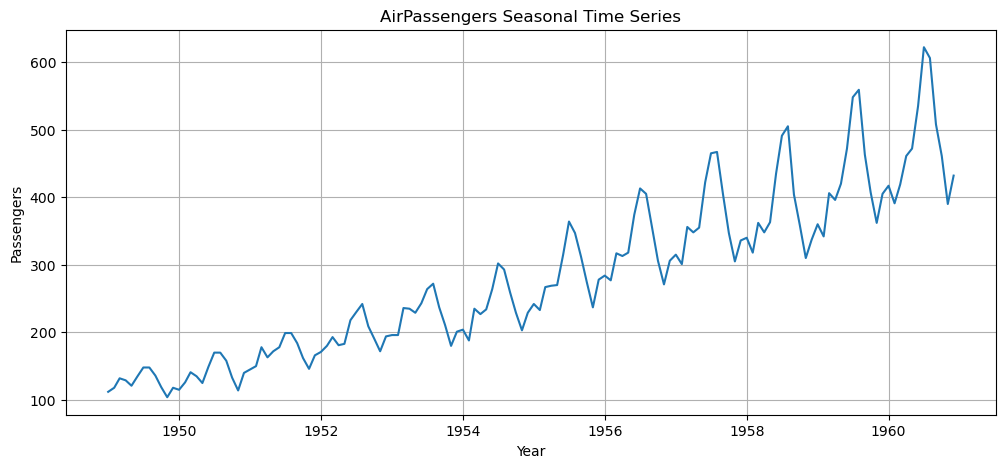

In [21]:
plt.figure(figsize=(12, 5))

plt.plot(series)

plt.title("AirPassengers Seasonal Time Series")
plt.xlabel("Year")
plt.ylabel("Passengers")

plt.show()

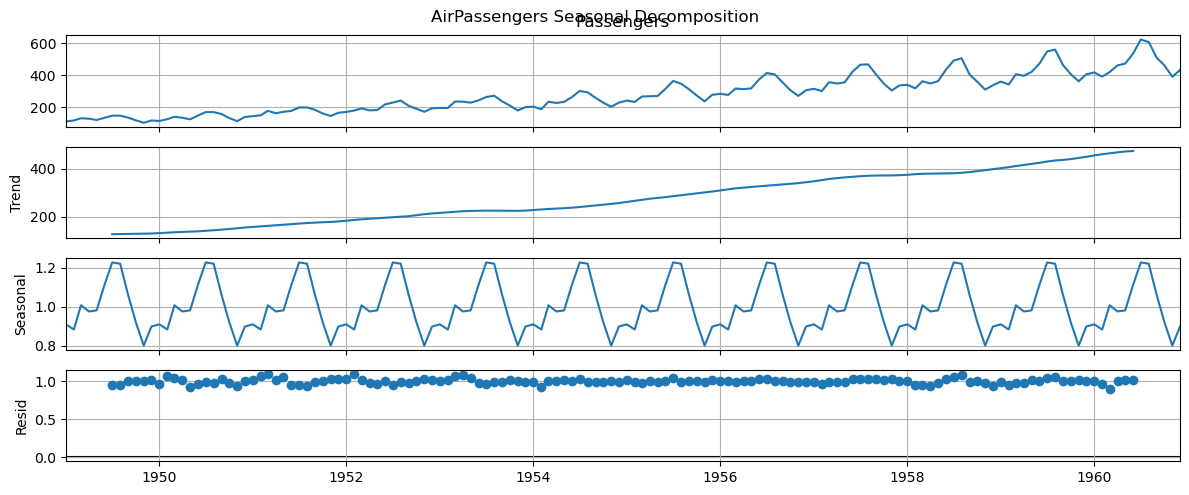

In [22]:
decomposition = seasonal_decompose(
    series,
    model="multiplicative",
    period=12
)

decomposition.plot()

plt.suptitle("AirPassengers Seasonal Decomposition")

plt.show()

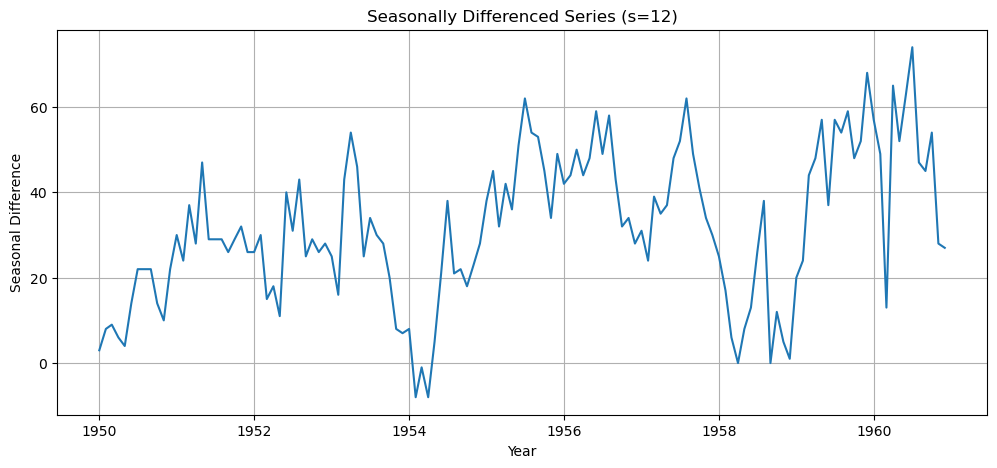

Stationarity After Seasonal Differencing:
ADF Statistic: -3.3830207264924796
p-value: 0.011551493085515008
Conclusion: Series is Stationary


In [23]:
seasonal_diff = series.diff(12).dropna()

plt.figure(figsize=(12, 5))

plt.plot(seasonal_diff)

plt.title("Seasonally Differenced Series (s=12)")
plt.xlabel("Year")
plt.ylabel("Seasonal Difference")

plt.show()

print("Stationarity After Seasonal Differencing:")

check_stationarity(seasonal_diff)

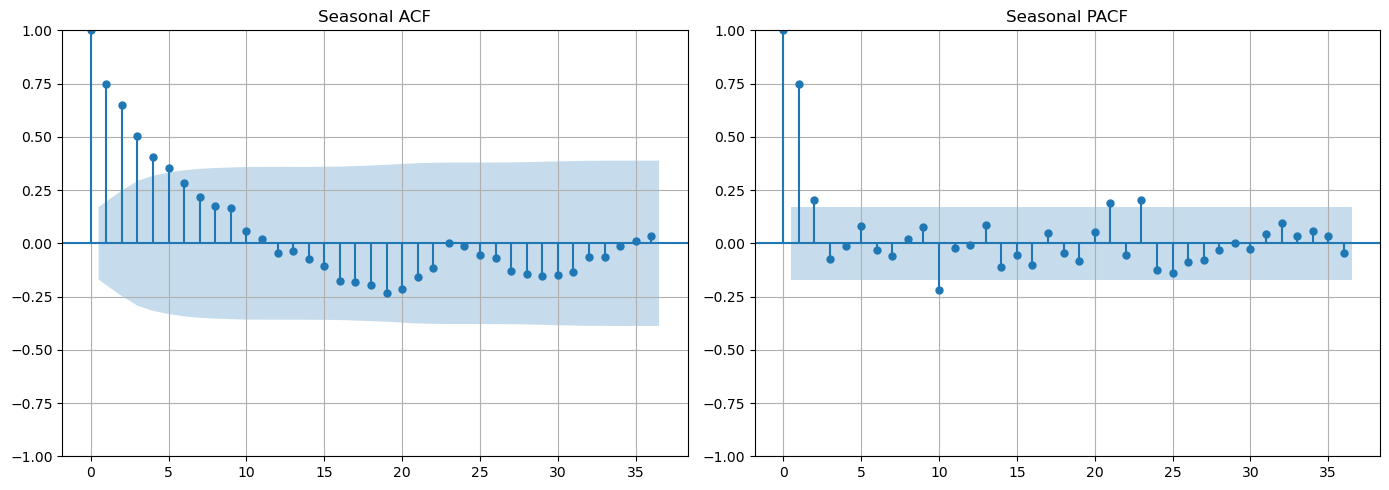

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(seasonal_diff, lags=36, ax=axes[0])

plot_pacf(
    seasonal_diff,
    lags=36,
    method="ywm",
    ax=axes[1]
)

axes[0].set_title("Seasonal ACF")
axes[1].set_title("Seasonal PACF")

plt.tight_layout()
plt.show()

In [25]:
sarima_train_size = int(len(series) * 0.80)

sarima_train = series.iloc[:sarima_train_size]
sarima_test = series.iloc[sarima_train_size:]

print("Training Size:", len(sarima_train))
print("Testing Size:", len(sarima_test))

print("Training Period:", sarima_train.index.min(),
      "to", sarima_train.index.max())

print("Testing Period:", sarima_test.index.min(),
      "to", sarima_test.index.max())

Training Size: 115
Testing Size: 29
Training Period: 1949-01-01 00:00:00 to 1958-07-01 00:00:00
Testing Period: 1958-08-01 00:00:00 to 1960-12-01 00:00:00


In [26]:
sarima_model = SARIMAX(
    sarima_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Sun, 01 Nov 2026   AIC                            657.601
Time:                                    22:44:54   BIC                            669.988
Sample:                                01-01-1949   HQIC                           662.592
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0.184     -4.461      0.000      -1.184      -0.461
ma.L1          0.7176      0.224   

In [27]:
sarima_forecast = sarima_fit.forecast(
    steps=len(sarima_test)
)

sarima_mae = mean_absolute_error(
    sarima_test, sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(sarima_test, sarima_forecast)
)

print("SARIMA(1,1,1)(1,1,1,12) RESULTS")

print("MAE:", round(sarima_mae, 3))
print("RMSE:", round(sarima_rmse, 3))
print("AIC:", round(sarima_fit.aic, 3))

SARIMA(1,1,1)(1,1,1,12) RESULTS
MAE: 25.268
RMSE: 31.787
AIC: 657.601


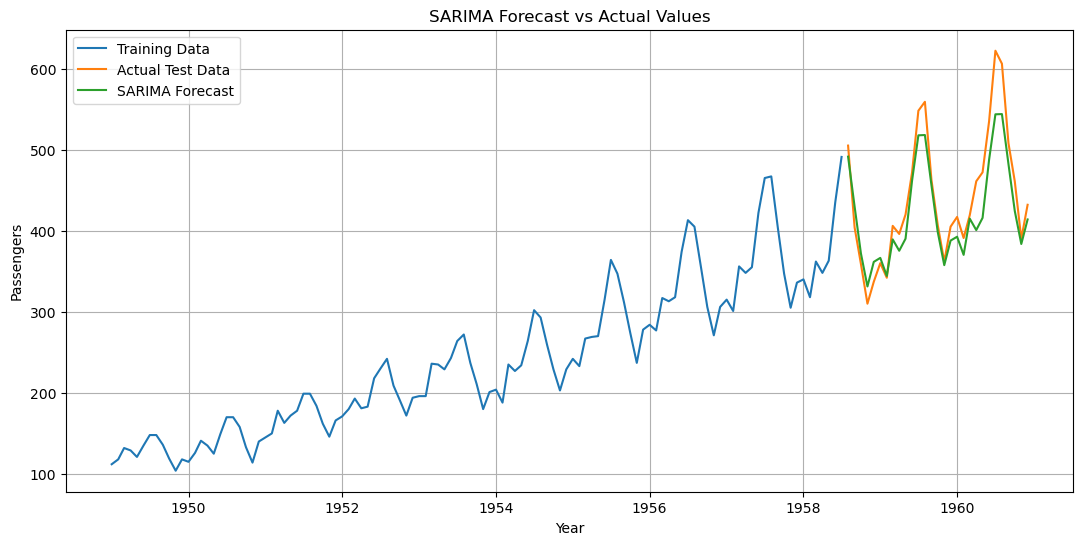

In [28]:
plt.figure(figsize=(13, 6))

plt.plot(sarima_train, label="Training Data")
plt.plot(sarima_test, label="Actual Test Data")
plt.plot(sarima_forecast, label="SARIMA Forecast")

plt.title("SARIMA Forecast vs Actual Values")
plt.xlabel("Year")
plt.ylabel("Passengers")

plt.legend()
plt.show()

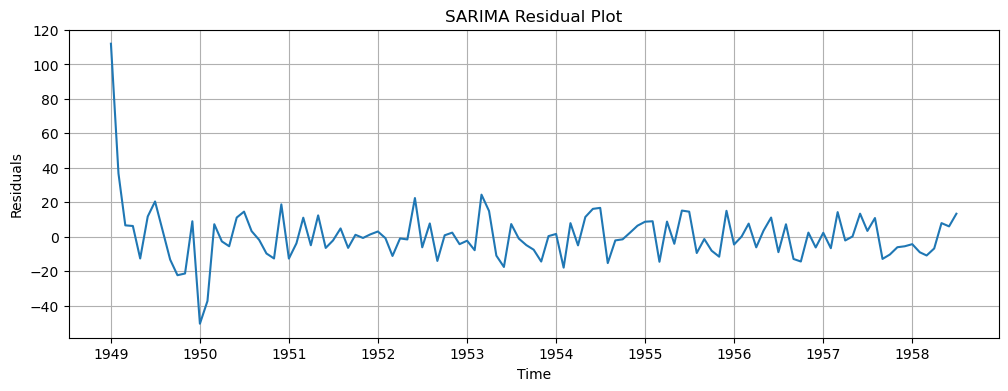

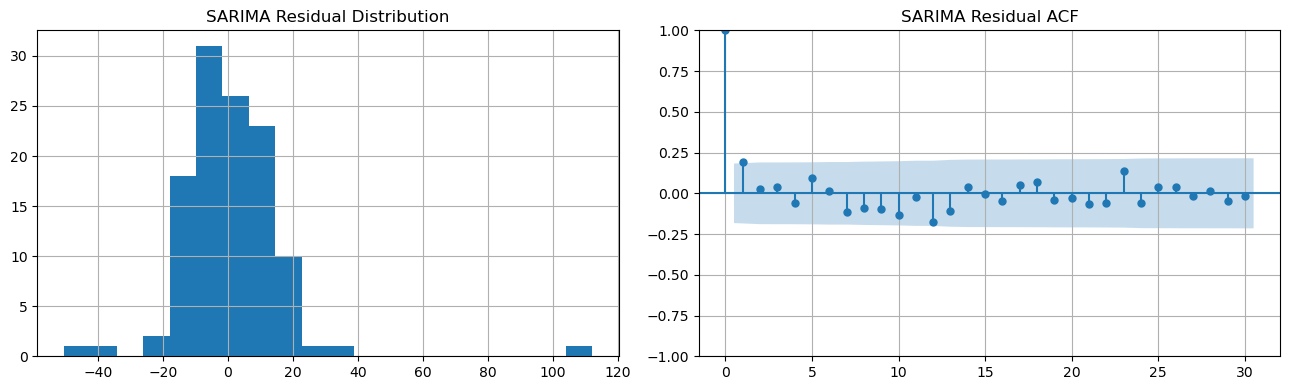

In [29]:
sarima_residuals = sarima_fit.resid

plt.figure(figsize=(12, 4))

plt.plot(sarima_residuals)

plt.title("SARIMA Residual Plot")
plt.xlabel("Time")
plt.ylabel("Residuals")

plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(sarima_residuals, bins=20)
axes[0].set_title("SARIMA Residual Distribution")

plot_acf(
    sarima_residuals.dropna(),
    lags=30,
    ax=axes[1]
)

axes[1].set_title("SARIMA Residual ACF")

plt.tight_layout()
plt.show()

In [30]:
sarima_configs = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((0, 1, 1), (0, 1, 1, 12)),
    ((1, 1, 0), (1, 1, 0, 12))
]

sarima_results = []

for order, seasonal_order in sarima_configs:

    print("Testing:", order, seasonal_order)

    model = SARIMAX(
        sarima_train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(disp=False)

    forecast = fitted_model.forecast(
        steps=len(sarima_test)
    )

    mae = mean_absolute_error(
        sarima_test, forecast
    )

    rmse = np.sqrt(
        mean_squared_error(sarima_test, forecast)
    )

    sarima_results.append({
        "ARIMA Order": str(order),
        "Seasonal Order": str(seasonal_order),
        "AIC": fitted_model.aic,
        "MAE": mae,
        "RMSE": rmse
    })

sarima_comparison = pd.DataFrame(sarima_results)

display(sarima_comparison.round(3))

print("Best SARIMA configuration based on RMSE:")

display(
    sarima_comparison.sort_values("RMSE").head(1)
)

Testing: (1, 1, 1) (1, 1, 1, 12)
Testing: (0, 1, 1) (0, 1, 1, 12)
Testing: (1, 1, 0) (1, 1, 0, 12)


,ARIMA Order,Seasonal Order,AIC,MAE,RMSE
0,"(1, 1, 1)","(1, 1, 1, 12)",657.601,25.268,31.787
1,"(0, 1, 1)","(0, 1, 1, 12)",659.342,24.059,30.580
2,"(1, 1, 0)","(1, 1, 0, 12)",666.510,23.895,30.426


Best SARIMA configuration based on RMSE:


,ARIMA Order,Seasonal Order,AIC,MAE,RMSE
2,"(1, 1, 0)","(1, 1, 0, 12)",666.51006,23.89513,30.42577


In [31]:
# ARIMA model
arima_comparison_model = ARIMA(
    sarima_train,
    order=(2, 1, 2)
).fit()

arima_comparison_forecast = arima_comparison_model.forecast(
    steps=len(sarima_test)
)

# SARIMA model
sarima_comparison_model = SARIMAX(
    sarima_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_comparison_forecast = sarima_comparison_model.forecast(
    steps=len(sarima_test)
)

# Compare metrics
comparison = pd.DataFrame({

    "Model": ["ARIMA", "SARIMA"],

    "MAE": [
        mean_absolute_error(
            sarima_test, arima_comparison_forecast
        ),
        mean_absolute_error(
            sarima_test, sarima_comparison_forecast
        )
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(
            sarima_test, arima_comparison_forecast
        )),
        np.sqrt(mean_squared_error(
            sarima_test, sarima_comparison_forecast
        ))
    ]
})

display(comparison.round(3))

,Model,MAE,RMSE
0,ARIMA,63.545,82.513
1,SARIMA,25.268,31.787


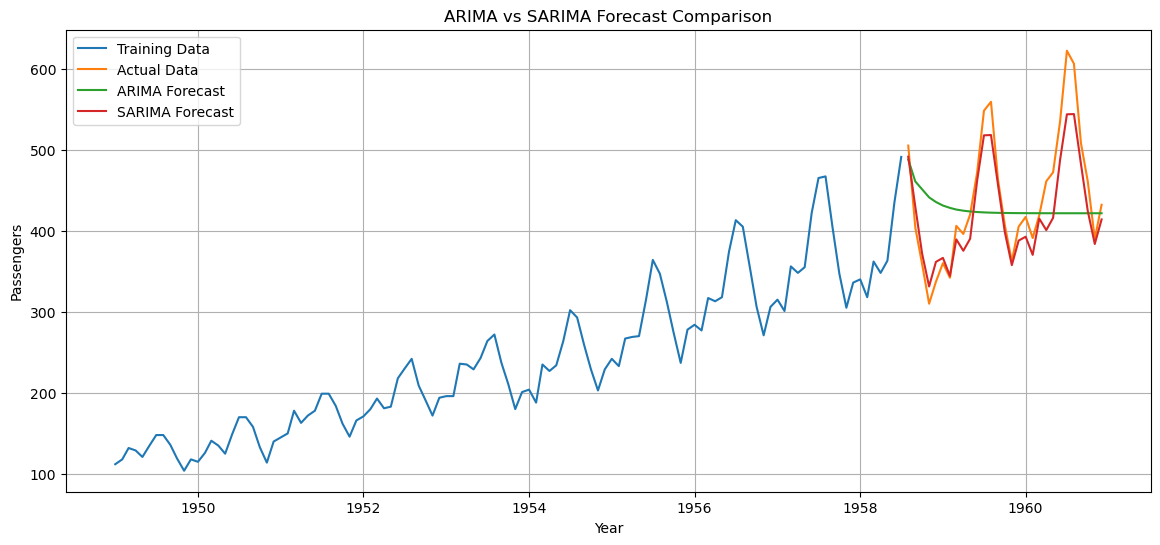

In [32]:
plt.figure(figsize=(14, 6))

plt.plot(sarima_train, label="Training Data")
plt.plot(sarima_test, label="Actual Data")

plt.plot(
    sarima_test.index,
    arima_comparison_forecast,
    label="ARIMA Forecast"
)

plt.plot(
    sarima_test.index,
    sarima_comparison_forecast,
    label="SARIMA Forecast"
)

plt.title("ARIMA vs SARIMA Forecast Comparison")

plt.xlabel("Year")
plt.ylabel("Passengers")

plt.legend()
plt.show()

In [33]:
seasonal_d_results = []

for D in [0, 1]:

    model = SARIMAX(
        sarima_train,
        order=(1, 1, 1),
        seasonal_order=(1, D, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(disp=False)

    forecast = fitted_model.forecast(
        steps=len(sarima_test)
    )

    mae = mean_absolute_error(
        sarima_test, forecast
    )

    rmse = np.sqrt(
        mean_squared_error(sarima_test, forecast)
    )

    seasonal_d_results.append({
        "Seasonal Differencing (D)": D,
        "AIC": fitted_model.aic,
        "MAE": mae,
        "RMSE": rmse
    })

seasonal_d_comparison = pd.DataFrame(seasonal_d_results)

display(seasonal_d_comparison.round(3))

,Seasonal Differencing (D),AIC,MAE,RMSE
0,0,721.684,18.697,22.399
1,1,657.601,25.268,31.787


In [34]:
import scipy
import numpy

print("SciPy version:", scipy.__version__)
print("NumPy version:", numpy.__version__)

SciPy version: 1.18.1
NumPy version: 2.5.4


In [35]:
import statsmodels.api as sm

co2_data = sm.datasets.co2.load_pandas().data

print("Original CO2 Dataset:")
display(co2_data.head())

# Convert weekly observations into monthly averages
co2_series = co2_data["co2"].resample("MS").mean()

# Handle missing observations
co2_series = co2_series.interpolate(
    method="time",
    limit_direction="both"
)

co2_series = co2_series.astype(float)

print("\nProcessed CO2 Dataset:")
display(co2_series.head())

print("\nTotal Monthly Observations:", len(co2_series))

Original CO2 Dataset:


,co2
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4



Processed CO2 Dataset:


1958-03-01    316.100000
1958-04-01    317.200000
1958-05-01    317.433333
1958-06-01    316.514344
1958-07-01    315.625000
Freq: MS, Name: co2, dtype: float64


Total Monthly Observations: 526


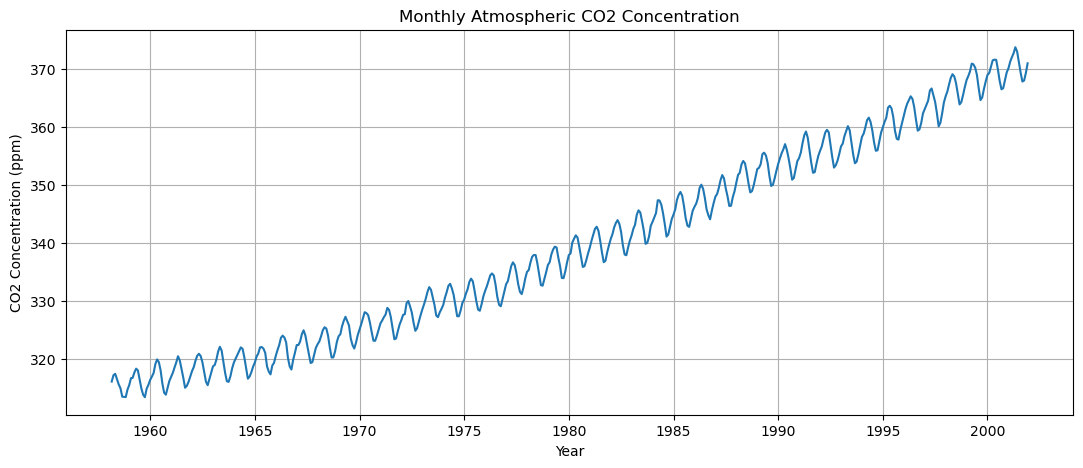

In [36]:
plt.figure(figsize=(13, 5))

plt.plot(co2_series)

plt.title("Monthly Atmospheric CO2 Concentration")
plt.xlabel("Year")
plt.ylabel("CO2 Concentration (ppm)")

plt.show()

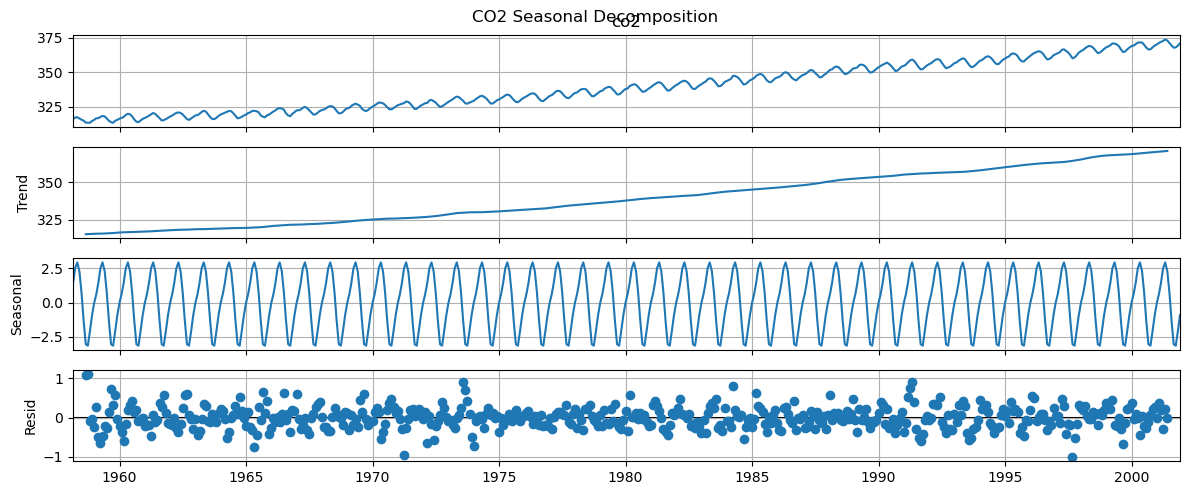

In [37]:
co2_decomposition = seasonal_decompose(
    co2_series,
    model="additive",
    period=12
)

co2_decomposition.plot()

plt.suptitle("CO2 Seasonal Decomposition")

plt.show()

In [38]:
co2_split = int(len(co2_series) * 0.80)

co2_train = co2_series.iloc[:co2_split]
co2_test = co2_series.iloc[co2_split:]

co2_model = SARIMAX(
    co2_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

co2_fit = co2_model.fit(disp=False)

print(co2_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                co2   No. Observations:                  420
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 -85.986
Date:                            Sun, 01 Nov 2026   AIC                            181.972
Time:                                    22:45:44   BIC                            201.841
Sample:                                03-01-1958   HQIC                           189.846
                                     - 02-01-1993                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2522      0.118      2.130      0.033       0.020       0.484
ma.L1         -0.5980      0.102   

CO2 SARIMA RESULTS
MAE: 1.852
RMSE: 2.184
AIC: 181.972


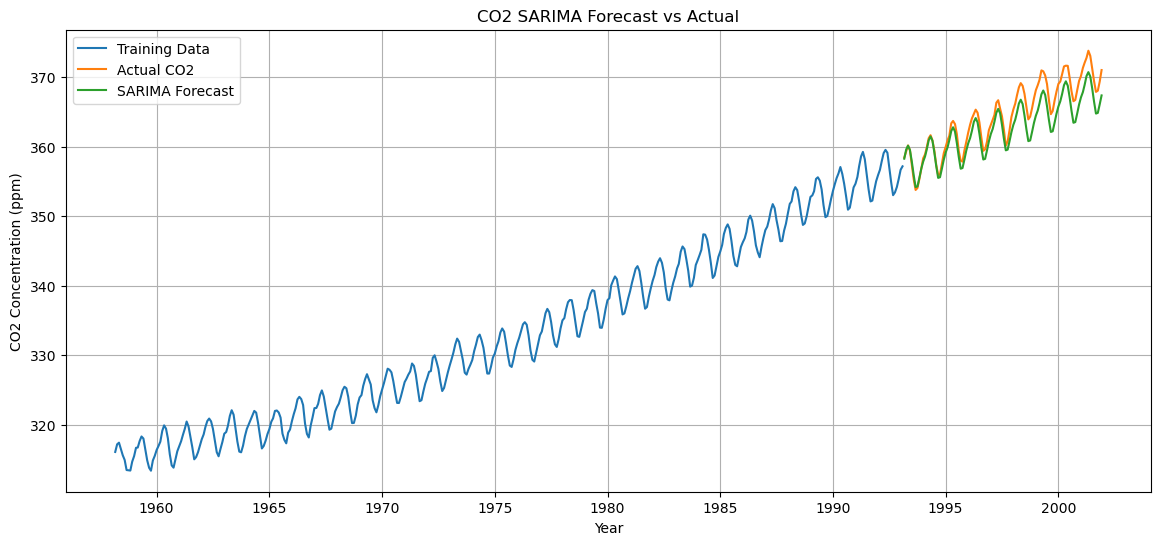

In [39]:
co2_forecast = co2_fit.forecast(
    steps=len(co2_test)
)

co2_mae = mean_absolute_error(
    co2_test, co2_forecast
)

co2_rmse = np.sqrt(
    mean_squared_error(co2_test, co2_forecast)
)

print("CO2 SARIMA RESULTS")

print("MAE:", round(co2_mae, 3))
print("RMSE:", round(co2_rmse, 3))
print("AIC:", round(co2_fit.aic, 3))

plt.figure(figsize=(14, 6))

plt.plot(co2_train, label="Training Data")
plt.plot(co2_test, label="Actual CO2")
plt.plot(co2_forecast, label="SARIMA Forecast")

plt.title("CO2 SARIMA Forecast vs Actual")

plt.xlabel("Year")
plt.ylabel("CO2 Concentration (ppm)")

plt.legend()
plt.show()

In [40]:
final_results = pd.DataFrame({

    "Model": [
        "ARIMA(2,1,2)",
        "SARIMA(1,1,1)(1,1,1,12)",
        "Sunspots ARIMA",
        "CO2 SARIMA"
    ],

    "MAE": [
        mean_absolute_error(test, arima_forecast),
        sarima_mae,
        sunspot_mae,
        co2_mae
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(test, arima_forecast)),
        sarima_rmse,
        sunspot_rmse,
        co2_rmse
    ],

    "AIC": [
        arima_fit.aic,
        sarima_fit.aic,
        sunspot_fit.aic,
        co2_fit.aic
    ]
})

display(final_results.round(3))

print("Both Lab Exercises Completed Successfully!")

,Model,MAE,RMSE,AIC
0,"ARIMA(2,1,2)",63.545,82.513,1057.516
1,"SARIMA(1,1,1)(1,1,1,12)",25.268,31.787,657.601
2,Sunspots ARIMA,33.161,40.228,2020.545
3,CO2 SARIMA,1.852,2.184,181.972


Both Lab Exercises Completed Successfully!
